# Análise de Cancelamento de Clientes (Churn) — Terra Signal

Neste projeto, organizamos os dados dos clientes da **Terra Signal** para entender quem são nossos assinantes, o que eles contratam e o que os leva a cancelar os serviços.

### Perguntas que vamos responder:
1. Qual é o sentimento geral dos clientes em relação aos serviços da empresa?
2. O tipo de contrato influencia diretamente na taxa de cancelamento?
3. Quais formas de pagamento são mais comuns na carteira e como elas se relacionam com a permanência?
4. Como o feedback escrito (sentimento negativo ou positivo) reflete o risco de saída do cliente?

## 1. Preparação e Leitura dos Dados (Camada Bronze)
Nesta primeira etapa, carregamos as ferramentas necessárias e abrimos a base original (`history.csv`) exatamente como ela veio do sistema, sem alterações.

### Bibliotecas utilizadas
Importamos o `pandas` para manipular as tabelas e o `matplotlib` / `seaborn` para montar os gráficos.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv("history.csv")

### Explorando os dados brutos
Olhamos as primeiras e últimas linhas da tabela para conferir se a leitura funcionou bem e identificar possíveis problemas logo de cara.

In [7]:
#primeira vizualização do dataframe
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
0,4578-PHJYZ,Male,0,Yes,Yes,52,Yes,No,DSL,No,...,Yes,No,One year,Yes,Electronic check,68.75,3482.85,No,I have been a customer with this internet prov...,6532
1,6289-CPNLD,Male,0,Yes,Yes,33,Yes,No,DSL,No,...,Yes,Yes,One year,Yes,Mailed check,73.90,2405.05,Yes,I've been a customer with this company for ove...,7634
2,2682-KEVRP,Female,1,No,No,22,Yes,No,No,No internet service,...,No internet service,No internet service,One year,Yes,Mailed check,20.05,417.00,No,I have been a customer with this company for 2...,3628
3,5697-GOMBF,Female,1,Yes,Yes,28,No,No phone service,DSL,No,...,Yes,No,Month-to-month,Yes,Electronic check,35.90,973.65,No,I have been a customer with this internet prov...,7851
4,9717-QEBGU,Male,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.30,144.00,No,I have been using the fiber optic internet ser...,1691
5,6797-LNAQX,Male,0,Yes,Yes,70,Yes,Yes,Fiber optic,No,...,Yes,Yes,Two year,No,Bank transfer (automatic),98.30,6859.50,Yes,I have been a customer with this company for 7...,5487
6,3050-GBUSH,Female,0,No,No,3,no,No phone service,DSL,No,...,Yes,No,Month-to-month,Yes,Credit card (automatic),34.80,113.95,No,I have been a customer with this DSL internet ...,6382
7,8020-BWHYL,Female,1,No,No,15,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Credit card (automatic),75.30,NaN,Yes,I recently canceled my service with this provi...,353
8,6752-APNJL,Male,0,Yes,Yes,42,Yes,No,DSL,Yes,...,No,No,Month-to-month,No,Mailed check,54.50,2301.15,No,I have been a customer with this company for 4...,2436
9,1760-CAZHT,Male,0,No,Yes,25,Yes,No,No,No internet service,...,No internet service,No internet service,Month-to-month,No,Mailed check,20.80,460.20,No,I have been a customer with this company for 2...,7049


In [8]:
df.tail(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
5624,8869-LIHMK,Female,0,No,No,64,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Two year,Yes,Bank transfer (automatic),115.10,7334.05,No,I have been a loyal customer of this company f...,5342
5625,0932-YIXYU,Female,0,No,No,47,yes,No,No,No internet service,...,No internet service,No internet service,Two year,No,Credit card (automatic),20.25,1029.80,No,I have been a customer with this company for a...,9229
5626,3569-EDBPQ,Female,0,No,No,24,Yes,Yes,Fiber optic,Yes,...,No,No,Month-to-month,Yes,Electronic check,84.35,1938.05,No,I have been a customer with this fiber optic i...,7165
5627,8645-KOMJQ,Male,0,Yes,Yes,69,Yes,Yes,DSL,No,...,Yes,Yes,Two year,Yes,Bank transfer (automatic),81.95,5601.40,No,I have been a loyal customer with this company...,411
5628,0786-IVLAW,Female,1,No,No,66,Yes,Yes,Fiber optic,No,...,Yes,Yes,One year,No,Bank transfer (automatic),108.10,7238.60,No,I have been a customer with this company for 6...,5113
5629,8909-BOLNL,Male,0,No,No,3,Yes,No,No,No internet service,...,No internet service,No internet service,One year,No,Mailed check,21.20,52.05,No,I have been a customer with this company for 3...,8354
5630,2832-KJCRD,Female,0,No,No,38,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,103.65,3988.50,No,I have been a customer with this company for 3...,9308
5631,7975-JMZNT,Male,0,Yes,No,66,Yes,Yes,DSL,Yes,...,Yes,Yes,Two year,No,Bank transfer (automatic),91.70,6075.90,No,I have been a customer with this DSL internet ...,2113
5632,4250-ZBWLV,Male,0,No,No,68,Yes,Yes,Fiber optic,No,...,Yes,Yes,One year,No,Electronic check,108.45,7176.55,Yes,I have been a customer with this company for o...,3904
5633,3915-ODIYG,Male,1,No,No,60,Yes,Yes,DSL,Yes,...,No,Yes,One year,Yes,Electronic check,71.75,4374.55,No,I have been a loyal customer of this internet ...,3016


### O que significa cada coluna
Abaixo está o resumo do que cada campo representa na base original:

| Coluna           | Tradução                 | Definição resumida                                        |
| ---------------- | ------------------------ | --------------------------------------------------------- |
| customerID       | ID do cliente            | Código único de identificação do cliente.                 |
| gender           | Gênero                   | Gênero do cliente.                                        |
| SeniorCitizen    | Cidadão idoso            | Indica se o cliente é idoso (1 = sim, 0 = não).           |
| Partner          | Parceiro(a)              | Indica se o cliente possui companheiro(a).                |
| Dependents       | Dependentes              | Indica se o cliente possui dependentes.                   |
| tenure           | Tempo de permanência     | Tempo de relacionamento com a empresa, em meses.          |
| PhoneService     | Serviço telefônico       | Indica se o cliente possui telefone contratado.           |
| MultipleLines    | Múltiplas linhas         | Indica se possui mais de uma linha telefônica.            |
| InternetService  | Serviço de internet      | Tipo de serviço de internet contratado.                   |
| OnlineSecurity   | Segurança online         | Indica se possui serviço de segurança digital.            |
| OnlineBackup     | Backup online            | Indica se possui cópia de segurança de arquivos na nuvem. |
| DeviceProtection | Proteção de dispositivos | Indica se possui proteção para seus dispositivos.         |
| TechSupport      | Suporte técnico          | Indica se possui assistência técnica contratada.          |
| StreamingTV      | Transmissão de TV        | Indica se possui serviço de streaming de televisão.       |
| StreamingMovies  | Streaming de filmes      | Indica se possui serviço de streaming de filmes.          |
| Contract         | Contrato                 | Tipo e duração do contrato do cliente.                    |
| PaperlessBilling | Faturamento sem papel    | Indica se recebe a fatura digitalmente.                   |
| PaymentMethod    | Método de pagamento      | Forma utilizada para pagar pelos serviços.                |
| MonthlyCharges   | Cobranças mensais        | Valor cobrado mensalmente pelos serviços.                 |
| TotalCharges     | Cobranças totais         | Valor total acumulado cobrado do cliente.                 |
| Churn            | Cancelamento             | Indica se o cliente cancelou o serviço.                   |
| CustomerFeedback | Feedback do cliente      | Comentário do cliente sobre sua experiência.              |
| MonthlyIncome    | Renda mensal             | Valor da renda mensal do cliente.                         |

### Verificando a estrutura da tabela
Checamos o tamanho da base (5.634 clientes), os formatos de cada coluna e onde existem campos vazios.

In [9]:
df.dtypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   str    
 1   gender            5634 non-null   str    
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   str    
 4   Dependents        5634 non-null   str    
 5   tenure            5634 non-null   str    
 6   PhoneService      5634 non-null   str    
 7   MultipleLines     5634 non-null   str    
 8   InternetService   5634 non-null   str    
 9   OnlineSecurity    5634 non-null   str    
 10  OnlineBackup      5634 non-null   str    
 11  DeviceProtection  5634 non-null   str    
 12  TechSupport       5634 non-null   str    
 13  StreamingTV       5634 non-null   str    
 14  StreamingMovies   5634 non-null   str    
 15  Contract          5634 non-null   str    
 16  PaperlessBilling  5634 non-null   str    
 17  Paymen

## 2. Limpeza e Organização (Camada Silver)
Aqui começamos a arrumar a casa: traduzimos os nomes das colunas para português, corrigimos tipos de dados errados e preenchemos informações faltantes.

### Traduzindo os nomes das colunas
Deixamos todas as colunas em português para facilitar a leitura e o trabalho do grupo.

In [10]:
dicionario_dados = {
    "Variável Original": [
        "customerID", "gender", "SeniorCitizen", "Partner", "Dependents", "tenure",
        "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
        "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
        "PaperlessBilling", "PaymentMethod", "MonthlyCharges", "TotalCharges", "Churn",
        "CustomerFeedback", "MonthlyIncome"
    ],
    "Variável Traduzida": [
        "clienteID", "genero", "idoso", "conjuge", "dependentes", "tempoDeServiço",
        "serviçoTelefonico", "multiplasLinhasTelefonicas", "serviçoDeInternet",
        "segurançaOnline", "backupOnline", "proteçaoDeDispositivo", "suporteTecnico",
        "streamingTV", "streamingDeFilmes", "contrato", "faturaDigital",
        "metodoDePagamento", "mensalidade", "totalDeEncargos", "cancelamento",
        "feedbackDoCliente", "rendaMensal"
    ]
}

traducao = dict(zip(
    dicionario_dados["Variável Original"],
    dicionario_dados["Variável Traduzida"]
))

df = df.rename(columns=traducao)

# Transforma o dicionário em um DataFrame do Pandas
df_dicionario = pd.DataFrame(dicionario_dados)

print(df_dicionario.to_string(index=False))


Variável Original         Variável Traduzida
       customerID                  clienteID
           gender                     genero
    SeniorCitizen                      idoso
          Partner                    conjuge
       Dependents                dependentes
           tenure             tempoDeServiço
     PhoneService          serviçoTelefonico
    MultipleLines multiplasLinhasTelefonicas
  InternetService          serviçoDeInternet
   OnlineSecurity            segurançaOnline
     OnlineBackup               backupOnline
 DeviceProtection      proteçaoDeDispositivo
      TechSupport             suporteTecnico
      StreamingTV                streamingTV
  StreamingMovies          streamingDeFilmes
         Contract                   contrato
 PaperlessBilling              faturaDigital
    PaymentMethod          metodoDePagamento
   MonthlyCharges                mensalidade
     TotalCharges            totalDeEncargos
            Churn               cancelamento
 CustomerF

### Ajustando o formato dos dados
Transformamos respostas de "Sim/Não" em valores lógicos (`True`/`False`), ajustamos categorias e convertemos textos numéricos (como `tempoDeServiço`) para números de verdade.

In [11]:
df["clienteID"] = df["clienteID"].astype("string")

mapa_genero = {"Male": True, "Female": False}
df["genero"] = df["genero"].map(mapa_genero).astype("bool")

mapa_idoso = {1: True, 0: False}
df["idoso"] = df["idoso"].map(mapa_idoso).astype("bool")

mapa_sim_nao = {"Yes": True, "No": False, "yes": True, "no": False}
df["conjuge"] = df["conjuge"].map(mapa_sim_nao).astype("bool")

df["dependentes"] = df["dependentes"].map(mapa_sim_nao).astype("bool")

df["tempoDeServiço"] = pd.to_numeric(
    df["tempoDeServiço"].replace("unknown", pd.NA),
    errors="coerce"
).astype("Int8")

df["serviçoTelefonico"] = df["serviçoTelefonico"].astype("category")

df["multiplasLinhasTelefonicas"] = df["multiplasLinhasTelefonicas"].astype("category")

df["serviçoDeInternet"] = df["serviçoDeInternet"].astype("category")

df["segurançaOnline"] = df["segurançaOnline"].astype("category")

df["backupOnline"] = df["backupOnline"].astype("category")

df["proteçaoDeDispositivo"] = df["proteçaoDeDispositivo"].astype("category")

df["suporteTecnico"] = df["suporteTecnico"].astype("category")

df["streamingTV"] = df["streamingTV"].astype("category")

df["streamingDeFilmes"] = df["streamingDeFilmes"].astype("category")

df["contrato"] = df["contrato"].astype("category")

df["faturaDigital"] = df["faturaDigital"].map(mapa_sim_nao).astype("bool")

df["metodoDePagamento"] = df["metodoDePagamento"].astype("category")

df["mensalidade"] = df["mensalidade"].astype("float64")

df["cancelamento"] = df["cancelamento"].map(mapa_sim_nao).astype("bool")

df["feedbackDoCliente"] = df["feedbackDoCliente"].astype("string")

df["rendaMensal"] = df["rendaMensal"].astype("int16")

### Corrigindo tempos de serviço desconhecidos
Alguns clientes estavam com o tempo de serviço marcado como "unknown". Como eles informaram há quanto tempo são clientes no próprio texto do feedback, recuperamos esses meses manualmente.

In [12]:
df.loc[1097,'tempoDeServiço'] = 48
df.loc[1791,'tempoDeServiço'] = 12
df.loc[1984,'tempoDeServiço'] = 72
df.loc[2361,'tempoDeServiço'] = 22
df.loc[2372,'tempoDeServiço'] = 1
df.loc[3837,'tempoDeServiço'] = 73
df.loc[5328,'tempoDeServiço'] = 72
df.loc[4875,'tempoDeServiço'] = 28
df.loc[1059,'tempoDeServiço'] = 72
df.loc[5324,'tempoDeServiço'] = 24
df.loc[3476,'tempoDeServiço'] = 4
df.loc[2896,'tempoDeServiço'] = 67
df.loc[3153,'tempoDeServiço'] = 64
df.loc[3388,'tempoDeServiço'] = 67
df.loc[2641,'tempoDeServiço'] = 36
df.loc[2936,'tempoDeServiço'] = 15
df.loc[2959,'tempoDeServiço'] = 67
df.loc[3300,'tempoDeServiço'] = 6
df.loc[3515,'tempoDeServiço'] = 5

### Conferindo valores vazios e inconsistências
Verificamos se ainda restam campos nulos na tabela. Encontramos 278 registros sem valor na coluna `totalDeEncargos`.

In [13]:
df.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   clienteID                   5634 non-null   string  
 1   genero                      5634 non-null   bool    
 2   idoso                       5634 non-null   bool    
 3   conjuge                     5634 non-null   bool    
 4   dependentes                 5634 non-null   bool    
 5   tempoDeServiço              5634 non-null   Int8    
 6   serviçoTelefonico           5634 non-null   category
 7   multiplasLinhasTelefonicas  5634 non-null   category
 8   serviçoDeInternet           5634 non-null   category
 9   segurançaOnline             5634 non-null   category
 10  backupOnline                5634 non-null   category
 11  proteçaoDeDispositivo       5634 non-null   category
 12  suporteTecnico              5634 non-null   category
 13  streamingTV                 5

In [14]:
df["rendaMensal"].unique()

array([6532, 7634, 3628, ..., 9308, 3904, 3016],
      shape=(4307,), dtype=int16)

In [15]:
df.isnull().sum()

clienteID                       0
genero                          0
idoso                           0
conjuge                         0
dependentes                     0
tempoDeServiço                  0
serviçoTelefonico               0
multiplasLinhasTelefonicas      0
serviçoDeInternet               0
segurançaOnline                 0
backupOnline                    0
proteçaoDeDispositivo           0
suporteTecnico                  0
streamingTV                     0
streamingDeFilmes               0
contrato                        0
faturaDigital                   0
metodoDePagamento               0
mensalidade                     0
totalDeEncargos               278
cancelamento                    0
feedbackDoCliente               0
rendaMensal                     0
dtype: int64

In [16]:
df["totalDeEncargos"].head(60)

0     3482.85
1     2405.05
2      417.00
3      973.65
4      144.00
5     6859.50
6      113.95
7         NaN
8     2301.15
9      460.20
10     478.75
11     278.40
12      50.45
13    2192.90
14    2369.70
15    2351.45
16    6341.45
17    7323.15
18      70.10
19      55.70
20    4415.75
21    7854.15
22      70.30
23    2386.85
24    3361.05
25    3673.60
26    1205.05
27    7321.05
28    3186.70
29    5305.05
30      25.25
31     207.40
32     818.05
33     403.35
34    1111.85
35      20.05
36      20.05
37    3942.45
38    1182.55
39    7719.50
40     246.50
41    1211.65
42    3252.00
43    2511.30
44     702.00
45    7372.65
46    5976.90
47    5832.00
48    7156.20
49        NaN
50     231.80
51     592.65
52    5706.20
53      79.80
54    1356.70
55     662.95
56     635.90
57    8033.10
58    6034.85
59     255.25
Name: totalDeEncargos, dtype: float64

In [17]:
for i, linha in df.iterrows():
    if linha.iloc[19:20].isnull().any():
        print(f"Linha: {i} | totalDeEncargos: {linha['totalDeEncargos']}")


Linha: 7 | totalDeEncargos: nan
Linha: 49 | totalDeEncargos: nan
Linha: 64 | totalDeEncargos: nan
Linha: 79 | totalDeEncargos: nan
Linha: 122 | totalDeEncargos: nan
Linha: 138 | totalDeEncargos: nan
Linha: 139 | totalDeEncargos: nan
Linha: 143 | totalDeEncargos: nan
Linha: 162 | totalDeEncargos: nan
Linha: 176 | totalDeEncargos: nan
Linha: 188 | totalDeEncargos: nan
Linha: 193 | totalDeEncargos: nan
Linha: 237 | totalDeEncargos: nan
Linha: 257 | totalDeEncargos: nan
Linha: 275 | totalDeEncargos: nan
Linha: 305 | totalDeEncargos: nan
Linha: 317 | totalDeEncargos: nan
Linha: 326 | totalDeEncargos: nan
Linha: 335 | totalDeEncargos: nan
Linha: 345 | totalDeEncargos: nan
Linha: 346 | totalDeEncargos: nan
Linha: 347 | totalDeEncargos: nan
Linha: 351 | totalDeEncargos: nan
Linha: 369 | totalDeEncargos: nan
Linha: 412 | totalDeEncargos: nan
Linha: 437 | totalDeEncargos: nan
Linha: 458 | totalDeEncargos: nan
Linha: 463 | totalDeEncargos: nan
Linha: 502 | totalDeEncargos: nan
Linha: 511 | totalD

### Preenchendo o total de encargos e salvando a camada Silver
Para não perder esses 278 clientes, calculamos o valor estimado multiplicando o `tempoDeServiço` pela `mensalidade`. Depois disso, salvamos a base limpa em `df_silver.csv`.

In [18]:
# Filtra apenas as linhas onde 'tempoDeServiço' é nulo (NaN)
nulos = df['tempoDeServiço'].isnull()
nulos = df['totalDeEncargos'].isnull()

#Substituir os nulos do "TotalDeEncargos"
multiplicando = df['tempoDeServiço'] * df['mensalidade']
df['totalDeEncargos'] = df['totalDeEncargos'].fillna(multiplicando)

# Mensalidade mostra somente duas casas após o zero
df['mensalidade'] = df['mensalidade'].round(2)

# Mostra o resultado na tela
df[['tempoDeServiço', 'totalDeEncargos', 'mensalidade']]

df.isnull().sum()


clienteID                     0
genero                        0
idoso                         0
conjuge                       0
dependentes                   0
tempoDeServiço                0
serviçoTelefonico             0
multiplasLinhasTelefonicas    0
serviçoDeInternet             0
segurançaOnline               0
backupOnline                  0
proteçaoDeDispositivo         0
suporteTecnico                0
streamingTV                   0
streamingDeFilmes             0
contrato                      0
faturaDigital                 0
metodoDePagamento             0
mensalidade                   0
totalDeEncargos               0
cancelamento                  0
feedbackDoCliente             0
rendaMensal                   0
dtype: int64

In [19]:
df.to_csv("df_silver.csv", index=False, sep=",", decimal=".", encoding="utf-8-sig")

In [20]:
df.loc[79, "feedbackDoCliente"]

'I have been a customer with this company for over three years now, and I have been mostly satisfied with the fiber optic internet service they provide. However, I recently decided to cancel my subscription due to the high monthly charges of $109.55. I found a better deal with another provider and felt it was time to make a change. I have always paid my bills on time with mailed checks, but the cost was just becoming too much for me to justify. Overall, I had a good experience with the internet service itself, but the pricing ultimately led me to churn.'

## 3. Enriquecimento e Preparação para Análise (Camada Gold)
Com a base limpa, preparamos os dados finais para responder às perguntas de negócio: traduzimos os comentários dos clientes do inglês para o português e classificamos o sentimento de cada feedback.

In [21]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from tqdm import tqdm

### Verificando o ambiente de processamento
Checamos se o computador tem placa de vídeo (GPU) disponível para acelerar a tradução ou se usará o processador comum (CPU).

In [22]:
device = 0 if torch.cuda.is_available() else -1
print(f"Iniciando tradução usando: {'GPU' if device == 0 else 'CPU'}")

Iniciando tradução usando: CPU


In [23]:
#pip install deep-translator tqdm

### Preparando os arquivos de apoio para tradução
Definimos o arquivo de controle (`checkpoint`) para salvar o progresso da tradução aos poucos e evitar perda de trabalho.

In [24]:
from deep_translator import GoogleTranslator
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor
import time, os

# Lê o df_silver (utf-8-sig por causa do BOM no início do arquivo)
df_silver = pd.read_csv("df_silver.csv", encoding="utf-8-sig")

COL_ORIGEM = "feedbackDoCliente"
COL_DESTINO = "feedbackDoClientePT"   # coluna nova, pra não perder o original
CHECKPOINT = "feedback_traduzido_checkpoint.csv"

## 4. Análises e Respostas às Perguntas de Negócio
Abaixo respondemos às perguntas propostas utilizando gráficos e indicadores extraídos da base.

### Pergunta 2: O tipo de contrato influencia nos cancelamentos?
**Resposta:** Sim, e muito. O gráfico mostra que a grande maioria dos cancelamentos acontece entre clientes com **contrato mensal (`Month-to-month`)**. Como não há fidelidade ou multa, esses clientes saem com muito mais facilidade do que quem assina planos de 1 ou 2 anos.

C:\Users\user\AppData\Local\Temp\ipykernel_14840\4127131424.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='contrato', y='cancelamento', data=df, estimator=sum, ci=None)


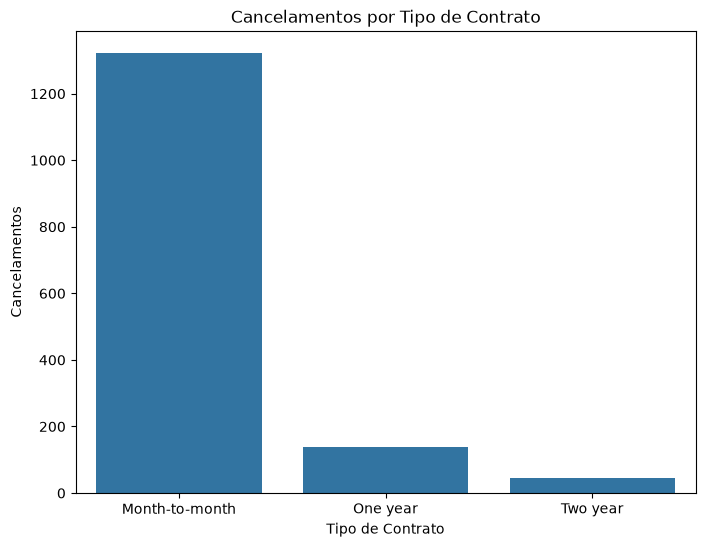

In [25]:
###cancelamentos por tipo de contrato
plt.figure(figsize=(8, 6))
sns.barplot(x='contrato', y='cancelamento', data=df, estimator=sum, ci=None)
plt.title('Cancelamentos por Tipo de Contrato')
plt.xlabel('Tipo de Contrato')
plt.ylabel('Cancelamentos')
plt.show()

### Pergunta 3: Como estão distribuídas as formas de pagamento dos clientes?
**Resposta:** O **cheque eletrônico (`Electronic check`)** é o meio mais usado, representando **33,6%** da carteira, seguido por cheque enviado pelo correio (`Mailed check`), transferência automática e cartão de crédito automático (cada um na faixa de 21% a 23%). Nos relatos dos clientes, pagamentos manuais (como envio de cheque) aparecem como um ponto de incômodo que motiva a troca de operadora.

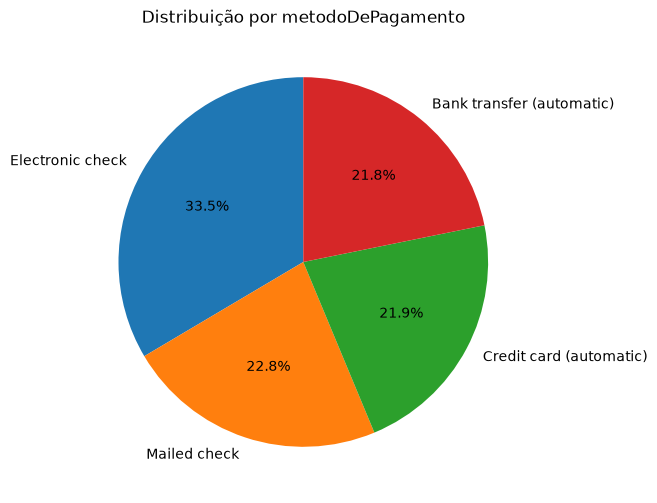

In [26]:
col_pizza = 'metodoDePagamento'
contagem = df[col_pizza].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(contagem.values, labels=contagem.index, autopct='%1.1f%%', startangle=90)
plt.title(f'Distribuição por {col_pizza}')
plt.show()


### Tradução dos feedbacks dos clientes
Para analisar os comentários escritos sem depender do inglês, usamos um modelo de tradução automática (`Helsinki-NLP`) para converter todos os textos para o português.

In [27]:
#%pip install transformers torch sentencepiece sacremoses

In [28]:
import truststore
truststore.inject_into_ssl()   # para o download passar pelo certificado da empresa

import torch
from transformers import MarianMTModel, MarianTokenizer

NOME_MODELO = "Helsinki-NLP/opus-mt-en-ROMANCE"
tokenizer = MarianTokenizer.from_pretrained(NOME_MODELO)
modelo = MarianMTModel.from_pretrained(NOME_MODELO)
modelo.eval()

print("GPU disponível:", torch.cuda.is_available())

Loading weights: 100%|██████████| 258/258 [00:00<00:00, 15326.98it/s]


GPU disponível: False


### Testando e aplicando a tradução em lotes
Primeiro testamos a tradução em 3 comentários para validar a qualidade e, em seguida, rodamos o processo para toda a base.

In [29]:
def traduzir_lote(textos):
    entrada = [">>pt<< " + t for t in textos]
    batch = tokenizer(entrada, return_tensors="pt", padding=True,
                      truncation=True, max_length=512)
    with torch.no_grad():
        saida = modelo.generate(**batch, num_beams=2, max_new_tokens=512)
    return tokenizer.batch_decode(saida, skip_special_tokens=True)

# Teste com 3 textos
amostra = df_silver["feedbackDoCliente"].head(3).tolist()
for en, pt in zip(amostra, traduzir_lote(amostra)):
    print("EN:", en)
    print("PT:", pt)
    print()

[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


EN: I have been a customer with this internet provider for over four years now and I have been satisfied with the service. The DSL internet is reliable and I have had no issues with connectivity. The monthly charges of $68.75 are reasonable for the service I receive. I appreciate the convenience of paying with electronic check. Overall, I am happy with my experience and have no plans to switch providers.
PT: Eu tenho sido um cliente com este fornecedor de internet por mais de quatro anos e eu tenho sido satisfeito com o serviço. A Internet DSL é confiável e eu não tive problemas com a conectividade. As taxas mensais de $68,75 são razoáveis para o serviço que eu recebo. Agradeço a conveniência de pagar com cheque eletrônico. Em geral, eu estou feliz com minha experiência e não tenho planos para trocar de fornecedores.

EN: I've been a customer with this company for over 2 and a half years now, and unfortunately I have decided to churn. The DSL internet service was reliable for the most 

In [30]:
import os
from tqdm import tqdm

COL_ORIGEM, COL_DESTINO = "feedbackDoCliente", "feedbackDoClientePT"
CHECKPOINT = "feedback_hf_checkpoint.csv"
TAM_LOTE = 16

if os.path.exists(CHECKPOINT):
    df_silver[COL_DESTINO] = pd.read_csv(CHECKPOINT, encoding="utf-8-sig")[COL_DESTINO]
elif COL_DESTINO not in df_silver.columns:
    df_silver[COL_DESTINO] = None

pendentes = df_silver.index[df_silver[COL_DESTINO].isna()].tolist()
print("Pendentes:", len(pendentes))

for k in tqdm(range(0, len(pendentes), TAM_LOTE), desc="Traduzindo"):
    idx = pendentes[k:k + TAM_LOTE]
    textos = df_silver.loc[idx, COL_ORIGEM].tolist()
    df_silver.loc[idx, COL_DESTINO] = traduzir_lote(textos)

    if (k // TAM_LOTE) % 10 == 0:   # checkpoint a cada 10 lotes
        df_silver[[COL_DESTINO]].to_csv(CHECKPOINT, index=False, encoding="utf-8-sig")

df_silver[[COL_DESTINO]].to_csv(CHECKPOINT, index=False, encoding="utf-8-sig")

Pendentes: 0


Traduzindo: 0it [00:00, ?it/s]


In [31]:
#carregando df original
df_silver = pd.read_csv("df_silver_traduzido.csv", encoding="utf-8-sig")

#carregando as traduções
df_checkpoint = pd.read_csv("feedback_hf_checkpoint.csv", encoding="utf-8-sig")

#confere o nome da coluna no checkpoint e junta de volta no df_silver
print("Colunas do checkpoint:", df_checkpoint.columns.tolist())

#juntando pelo índice (como index=False foi usado nos dois, a ordem das linhas é idêntica)
df_silver["feedbackDoClientePT"] = df_checkpoint.iloc[:, 0]

#comparação
print(df_silver[["feedbackDoCliente", "feedbackDoClientePT"]].head())

#criando df_silver_completo.csv com a coluna traduzida
df_silver.to_csv("df_silver_completo.csv", index=False, sep=",", decimal=".", encoding="utf-8-sig")

Colunas do checkpoint: ['feedbackDoClientePT']
                                   feedbackDoCliente  \
0  I have been a customer with this internet prov...   
1  I've been a customer with this company for ove...   
2  I have been a customer with this company for 2...   
3  I have been a customer with this internet prov...   
4  I have been using the fiber optic internet ser...   

                                 feedbackDoClientePT  
0  Eu tenho sido um cliente com este fornecedor d...  
1  Eu tenho sido um cliente com esta empresa por ...  
2  Eu tenho sido um cliente com esta empresa por ...  
3  Eu tenho sido um cliente com este fornecedor d...  
4  Eu tenho usado o serviço de internet de fibra ...  


### Consolidando a Camada Gold
Substituímos o texto em inglês pela versão em português na coluna principal para deixar a tabela final pronta para uso.

In [32]:
df_gold = pd.read_csv("df_silver_completo.csv", encoding="utf-8-sig")

In [33]:
df_gold = pd.read_csv("df_silver_completo.csv", encoding="utf-8-sig")
df_gold["feedbackDoCliente"] = df_gold["feedbackDoClientePT"]
df_gold = df_gold.drop(columns=["feedbackDoClientePT"])

In [34]:
df_gold.head(10)

,clienteID,genero,idoso,conjuge,dependentes,tempoDeServiço,serviçoTelefonico,multiplasLinhasTelefonicas,serviçoDeInternet,segurançaOnline,...,streamingTV,streamingDeFilmes,contrato,faturaDigital,metodoDePagamento,mensalidade,totalDeEncargos,cancelamento,feedbackDoCliente,rendaMensal
0,4578-PHJYZ,True,False,True,True,52,Yes,No,DSL,No,...,Yes,No,One year,True,Electronic check,68.75,3482.85,False,Eu tenho sido um cliente com este fornecedor d...,6532
1,6289-CPNLD,True,False,True,True,33,Yes,No,DSL,No,...,Yes,Yes,One year,True,Mailed check,73.90,2405.05,True,Eu tenho sido um cliente com esta empresa por ...,7634
2,2682-KEVRP,False,True,False,False,22,Yes,No,No,No internet service,...,No internet service,No internet service,One year,True,Mailed check,20.05,417.00,False,Eu tenho sido um cliente com esta empresa por ...,3628
3,5697-GOMBF,False,True,True,True,28,No,No phone service,DSL,No,...,Yes,No,Month-to-month,True,Electronic check,35.90,973.65,False,Eu tenho sido um cliente com este fornecedor d...,7851
4,9717-QEBGU,True,False,False,False,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,True,Electronic check,70.30,144.00,False,Eu tenho usado o serviço de internet de fibra ...,1691
5,6797-LNAQX,True,False,True,True,70,Yes,Yes,Fiber optic,No,...,Yes,Yes,Two year,False,Bank transfer (automatic),98.30,6859.50,True,Eu tenho sido um cliente com esta empresa por ...,5487
6,3050-GBUSH,False,False,False,False,3,no,No phone service,DSL,No,...,Yes,No,Month-to-month,True,Credit card (automatic),34.80,113.95,False,Tenho sido um cliente com este fornecedor de s...,6382
7,8020-BWHYL,False,True,False,False,15,Yes,No,Fiber optic,No,...,No,No,Month-to-month,True,Credit card (automatic),75.30,1129.50,True,Recentemente cancelei meu serviço com este for...,353
8,6752-APNJL,True,False,True,True,42,Yes,No,DSL,Yes,...,No,No,Month-to-month,False,Mailed check,54.50,2301.15,False,Eu tenho sido um cliente com esta empresa por ...,2436
9,1760-CAZHT,True,False,False,True,25,Yes,No,No,No internet service,...,No internet service,No internet service,Month-to-month,False,Mailed check,20.80,460.20,False,Eu tenho sido um cliente com esta empresa por ...,7049


### Classificando o sentimento dos comentários
Usamos a biblioteca **LeIA** (adaptada para o português) para ler cada comentário e classificar automaticamente se o cliente está **Positivo**, **Neutro** ou **Negativo**. O resultado final é salvo em `df_gold.csv`.

In [35]:
from leia import SentimentIntensityAnalyzer
analyzer = SentimentIntensityAnalyzer()

def analisar_leia(texto):
    if pd.isna(texto) or str(texto).strip() == "":
        return pd.Series([0.0, "Neutro"])
    
    scores = analyzer.polarity_scores(str(texto))
    compound = scores["compound"]
    
    if compound >= 0.05:
        sentimento = "Positivo"
    elif compound <= -0.05:
        sentimento = "Negativo"
    else:
        sentimento = "Neutro"
        
    return pd.Series([compound, sentimento])

#aplica na coluna traduzida em português
df_gold[["score_sentimento", "sentimento"]] = df_gold["feedbackDoCliente"].apply(analisar_leia)

df_gold.to_csv("df_gold.csv", index=False, sep=",", decimal=".", encoding="utf-8-sig")

### Pergunta 1 e 4: Qual é o sentimento geral da base e o que ele indica sobre o risco de saída?
**Resposta:** Dos 5.634 clientes analisados, **56,1%** demonstram sentimento positivo, enquanto **40,3%** expressam sentimento negativo (resultando em um saldo líquido positivo de **15,8 pontos**). Embora a maioria esteja satisfeita com a qualidade técnica (como velocidade da fibra), os 40,3% negativos representam uma fatia alta de clientes insatisfeitos — principalmente com o preço da mensalidade e cobranças — que estão em alerta vermelho para cancelar.

In [36]:
sns.set_theme(style="whitegrid")

COL_CHURN = "cancelamento"
COL_CONTRATO = "tipoContrato"
COL_MENSAL = "cobrancaMensal"

cores_sentimento = {"Positivo": "#2ecc71", "Neutro": "#95a5a6", "Negativo": "#e74c3c"}
ordem_sentimento = ["Positivo", "Neutro", "Negativo"]

pct_pos = (df_gold["sentimento"] == "Positivo").mean() * 100
pct_neg = (df_gold["sentimento"] == "Negativo").mean() * 100

print(f"Total de Clientes: {len(df_gold)}")
print(f"Score Médio de Polaridade: {df_gold['score_sentimento'].mean():.2f}")
print(f"Net Sentiment Score (NSS): {pct_pos - pct_neg:.1f} pts ({pct_pos:.1f}% Positivos - {pct_neg:.1f}% Negativos)")

Total de Clientes: 5634
Score Médio de Polaridade: 0.11
Net Sentiment Score (NSS): 15.8 pts (56.1% Positivos - 40.3% Negativos)


### Gráfico: Quantidade de clientes por sentimento

C:\Users\user\AppData\Local\Temp\ipykernel_14840\4009614358.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_gold, x="sentimento", order=ordem_sentimento, palette=cores_sentimento)


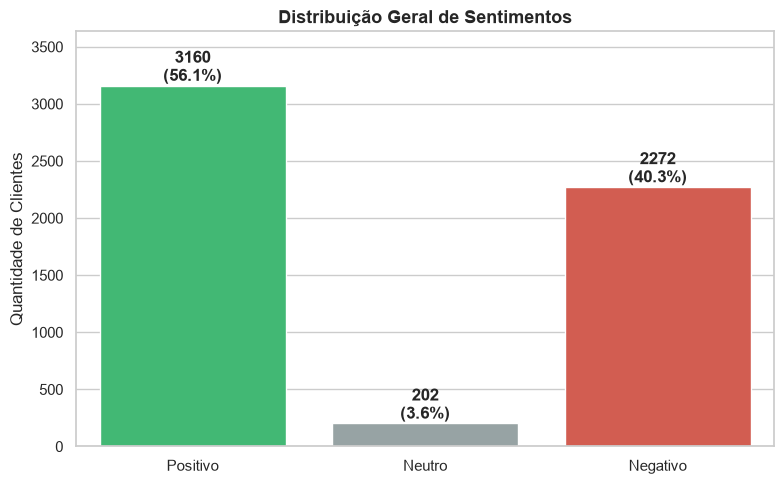

In [37]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_gold, x="sentimento", order=ordem_sentimento, palette=cores_sentimento)
plt.title("Distribuição Geral de Sentimentos", fontsize=13, fontweight="bold")
plt.xlabel("")
plt.ylabel("Quantidade de Clientes")
plt.ylim(0, df_gold["sentimento"].value_counts().max() * 1.15)

for p in ax.patches:
    qtd = int(p.get_height())
    ax.annotate(f"{qtd}\n({100 * qtd / len(df_gold):.1f}%)",
                (p.get_x() + p.get_width() / 2., qtd), ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

### Gráfico: Taxa de cancelamento por sentimento
Aqui cruzamos o sentimento identificado no comentário com o cancelamento real do cliente para validar se os relatos negativos realmente viram *churn*.

C:\Users\user\AppData\Local\Temp\ipykernel_14840\2880236267.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=taxa_churn, x="sentimento", y="taxa_pct", order=ordem_sentimento, palette=cores_sentimento)


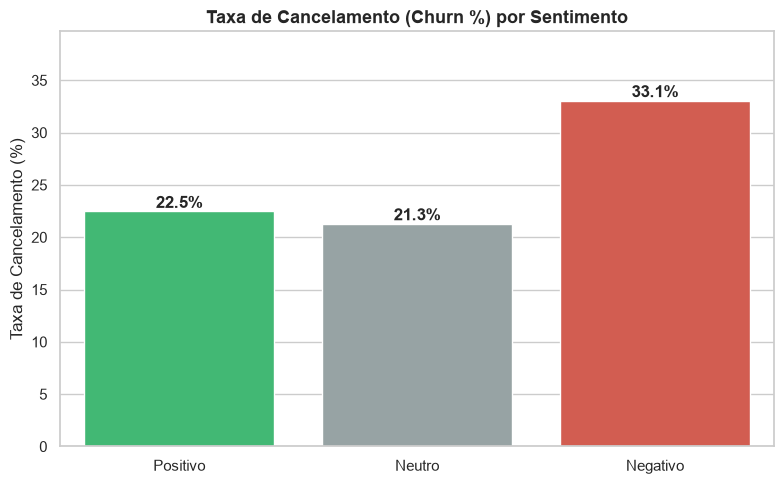

In [38]:
plt.figure(figsize=(8, 5))
taxa_churn = df_gold.groupby("sentimento", as_index=False)[COL_CHURN].mean()
taxa_churn["taxa_pct"] = taxa_churn[COL_CHURN] * 100

ax = sns.barplot(data=taxa_churn, x="sentimento", y="taxa_pct", order=ordem_sentimento, palette=cores_sentimento)
plt.title("Taxa de Cancelamento (Churn %) por Sentimento", fontsize=13, fontweight="bold")
plt.xlabel("")
plt.ylabel("Taxa de Cancelamento (%)")
plt.ylim(0, taxa_churn["taxa_pct"].max() * 1.2)

for p in ax.patches:
    val = p.get_height()
    ax.annotate(f"{val:.1f}%", (p.get_x() + p.get_width() / 2., val), ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()